# 03 · Finding damage from vibration: the digital twin at work

This is the inverse problem. A beam has a crack we cannot see. We measure its vibration (four natural frequencies,
and four mode shapes at nine sensors, all with noise) and ask:

**Where is the damage, how severe is it, and how sure are we?**

The detector (`beamtwin.damage.detect`) tries 18,281 candidate cracks, uses the hybrid surrogate to predict what the
sensors would read for each, and turns the mismatches into probabilities with Bayes' rule.

This notebook shows:

1. Two worked examples: an easy crack and a hard one.
2. How accuracy depends on where the crack is.
3. A summary of the accuracy study.

**Before running:** you need the trained surrogate (Step 3b) and the study results (Step 4a):

```
python -m beamtwin.damage.study
```

In [1]:
%load_ext autoreload
%autoreload 2

import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

from beamtwin.damage import Beam, SurrogateForward, detect, simulate_measurement
from beamtwin.plotting import INK, INK_2, MARKERS, MUTED, SURFACE, apply_style, figures_dir, project_root

apply_style()
ROOT, FIGURES = project_root(), figures_dir()
forward = SurrogateForward(ROOT / "models" / "surrogate_hybrid.pt")

# One hue, light to dark: used for "how much" (probability) and for ordered noise levels.
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
PROBABILITY_CMAP = LinearSegmentedColormap.from_list("probability", [SURFACE, *BLUE_RAMP])

## 1. Two worked examples

The same steel beam (1 m long, 50 × 10 mm) with medium sensor noise (frequencies ±0.2 %, mode shapes ±0.02).

- **Easy:** a 20 % stiffness loss at 30 % of the length, where the beam bends a lot.
- **Hard:** a 10 % stiffness loss at 85 % of the length, near the free tip, where a cantilever hardly bends.

Each map shows the probability of every candidate. Dark blue means likely. The open circle is the true damage
and the cross is the detector's best answer.

In [2]:
beam = Beam(length=1.0, width=0.05, thickness=0.01, E=200e9, rho=7850)
FREQ_NOISE, SHAPE_NOISE = 0.002, 0.02
examples = {"Easy: damage near the clamp": (0.30, 0.20), "Hard: damage near the free tip": (0.85, 0.10)}

rng = np.random.default_rng(7)
results = {}
for title, (loc, sev) in examples.items():
    measurement = simulate_measurement(beam, loc, sev, FREQ_NOISE, SHAPE_NOISE, rng)
    results[title] = detect(measurement, beam, forward, FREQ_NOISE, SHAPE_NOISE)
    r = results[title]
    inside = (r.location_interval[0] <= loc <= r.location_interval[1]) and (r.severity_interval[0] <= sev <= r.severity_interval[1])
    print(f"{title}\n  truth: location {loc * 100:.0f} %, severity {sev * 100:.0f} %\n  found: {r.summary()}"
          f"\n  truth inside both 90 % ranges: {'yes' if inside else 'no'}\n")

Easy: damage near the clamp
  truth: location 30 %, severity 20 %
  found: Damage at 29.5 % of the length (90 % range 27.5-31.5 %), severity 20.5 % (90 % range 18.0-23.0 %), P(damaged) = 1.00
  truth inside both 90 % ranges: yes

Hard: damage near the free tip
  truth: location 85 %, severity 10 %
  found: Damage at 78.5 % of the length (90 % range 74.5-83.5 %), severity 8.0 % (90 % range 5.5-10.5 %), P(damaged) = 0.99
  truth inside both 90 % ranges: no



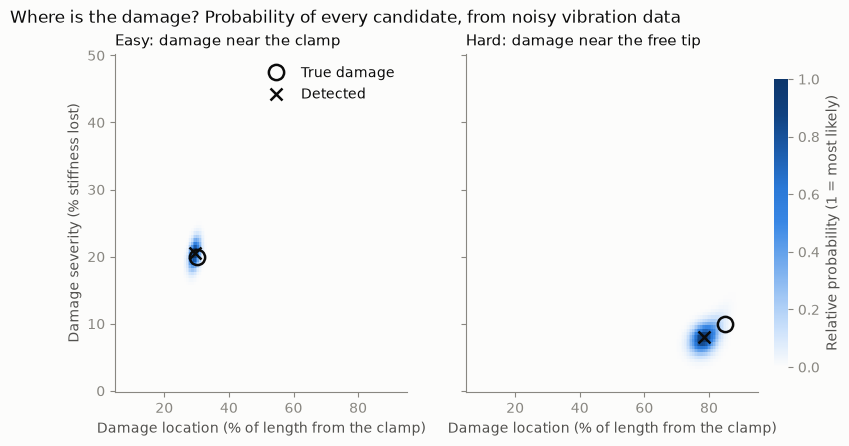

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, (title, result) in zip(axes, results.items()):
    loc, sev = examples[title]
    shown = result.posterior / result.posterior.max()             # scale so the most likely candidate = 1
    mesh = ax.pcolormesh(result.locations * 100, result.severities * 100, shown.T,
                         cmap=PROBABILITY_CMAP, vmin=0, vmax=1, shading="auto", rasterized=True)
    ax.plot(loc * 100, sev * 100, "o", markersize=11, markerfacecolor="none",
            markeredgecolor=INK, markeredgewidth=1.8, label="True damage")
    ax.plot(result.location * 100, result.severity * 100, "x", markersize=9, color=INK,
            markeredgewidth=1.8, label="Detected")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Damage location (% of length from the clamp)")
    ax.grid(False)
axes[0].set_ylabel("Damage severity (% stiffness lost)")
axes[0].legend(frameon=False, loc="upper right")
cbar = fig.colorbar(mesh, ax=axes, shrink=0.85, pad=0.02)
cbar.set_label("Relative probability (1 = most likely)")
cbar.outline.set_visible(False)
fig.suptitle("Where is the damage? Probability of every candidate, from noisy vibration data",
             x=0.02, ha="left", fontsize=12)
fig.savefig(FIGURES / "detection_examples.png", dpi=150, bbox_inches="tight")
plt.show()

Near the clamp the beam bends strongly in every mode, so damage there changes the vibration a lot and the
probability collapses onto a small spot around the truth. Near the free tip the beam hardly bends, so the same damage
changes the vibration much less, and the same sensor noise pushes the answer further: the spot can be wider, or
land noticeably away from the truth.

The 90 % ranges are meant to contain the truth 9 times in 10, so occasionally (about 1 time in 10) they miss.
The printout above says whether that happened in these examples. Section 3 checks how often it happens over many beams.

## 2. Detected vs. true location for every test beam

The accuracy study (Step 4a) tested 200 damaged beams at each of three noise levels. Each dot is one beam: on the
dashed line the detector found the damage exactly; dots far from it are misplaced damage.

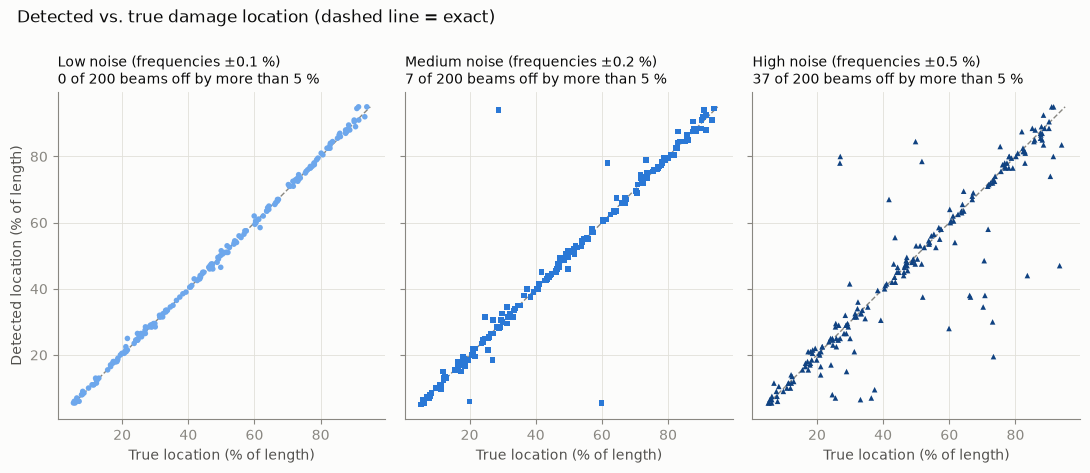

In [4]:
study = json.loads((ROOT / "data" / "processed" / "damage_study.json").read_text())
levels = list(study["noise_levels"])                       # low, medium, high
shade = {"low": BLUE_RAMP[2], "medium": BLUE_RAMP[4], "high": BLUE_RAMP[6]}

fig, axes = plt.subplots(1, 3, figsize=(11, 4.8), sharex=True, sharey=True)
for k, (ax, level) in enumerate(zip(axes, levels)):
    cases = [c for c in study["cases"][level] if c["true_severity"] > 0]
    true_loc = np.array([c["true_location"] for c in cases]) * 100
    found_loc = np.array([c["location"] for c in cases]) * 100
    far = np.abs(found_loc - true_loc) > 5
    ax.plot([5, 95], [5, 95], color=MUTED, linewidth=1, linestyle="--", zorder=1)
    ax.scatter(true_loc, found_loc, s=16, color=shade[level], marker=MARKERS[k], edgecolors="none", zorder=2)
    fn, sn = study["noise_levels"][level]
    ax.set_title(f"{level.capitalize()} noise (frequencies ±{fn * 100:.1f} %)\n"
                 f"{far.sum()} of {len(cases)} beams off by more than 5 %", loc="left", fontsize=10)
    ax.set_xlabel("True location (% of length)")
    ax.set_aspect("equal")
axes[0].set_ylabel("Detected location (% of length)")
fig.suptitle("Detected vs. true damage location (dashed line = exact)", x=0.02, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "detection_location_parity.png", dpi=150, bbox_inches="tight")
plt.show()

With low and medium noise almost every dot sits on the line. With high noise most still do, but a handful of beams
have their damage placed far from the truth: different damage that happens to produce almost the same vibration,
which noisy sensors cannot tell apart.

## 3. Summary of the accuracy study

In [5]:
rows = [
    ("Location error, median (% of length)", "location_error_median_pct", "{:.1f}"),
    ("Location error, 90th percentile (% of length)", "location_error_p90_pct", "{:.1f}"),
    ("Severity error, median (% points)", "severity_error_median_pts", "{:.1f}"),
    ("Severity error, 90th percentile (% points)", "severity_error_p90_pts", "{:.1f}"),
    ("Truth inside the 90 % location range", "location_interval_coverage", "{:.0%}"),
    ("Truth inside the 90 % severity range", "severity_interval_coverage", "{:.0%}"),
    ("Damaged beams flagged", "detection_rate", "{:.0%}"),
    ("Healthy beams flagged (false alarms)", "false_alarm_rate", "{:.0%}"),
    ("Time per detection (s)", "seconds_per_detection", "{:.3f}"),
]
print(f"{'':48s}" + "".join(f"{lvl:>9s}" for lvl in levels))
for label, key, fmt in rows:
    print(f"{label:48s}" + "".join(f"{fmt.format(study['summary'][lvl][key]):>9s}" for lvl in levels))

                                                      low   medium     high
Location error, median (% of length)                  0.3      0.5      1.3
Location error, 90th percentile (% of length)         1.0      2.6     16.6
Severity error, median (% points)                     0.4      1.0      1.9
Severity error, 90th percentile (% points)            1.2      2.8      6.9
Truth inside the 90 % location range                  82%      90%      92%
Truth inside the 90 % severity range                  89%      89%      90%
Damaged beams flagged                                100%      98%     100%
Healthy beams flagged (false alarms)                   0%       4%      32%
Time per detection (s)                              0.028    0.027    0.030


## What this shows

- With good sensors, the digital twin places damage to within about half a percent of the beam length in a typical
  case and estimates its severity to about one percentage point, in a few hundredths of a second.
- Its 90 % ranges contain the truth about 90 % of the time, so the stated uncertainty can be trusted. With very clean
  data it is slightly overconfident, because the surrogate's own small error starts to matter.
- Weak spots: occasional misplaced damage and frequent false alarms on healthy beams when sensors are noisy, and
  weaker sensitivity near the free tip, where the beam hardly bends. Better sensors, more modes, or repeated
  measurements would reduce these.